# 03 · Línea base de tarea única (TU)
**Fase 3, configuraciones TU-A / TU-B / TU-C (Secciones 4.4 y 4.5).**

Entrena mRoBERTa (`roberta-base-bne`) solo con MERGE traducido (p = 1) para predecir
valencia y activación, selecciona el mejor modelo por MSE de validación y evalúa en test:
MSE, Pearson, R² y el cuadrante derivado por signo frente a la línea base publicada.

Requiere haber ejecutado el notebook 01.

**Sin GPU el entrenamiento completo es muy lento** (mRoBERTa tiene 125 millones de parámetros).
Por eso empieza con `MODO_PRUEBA = True`: usa pocas letras, 1 época y secuencias cortas,
solo para comprobar que todo corre. Los números de ese modo no sirven para la tesis.

In [1]:
# Preparar rutas: la carpeta implementacion/ de tu computadora
import sys, os
from pathlib import Path

BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

CODIGO = BASE / 'codigo'
DATOS = BASE / 'datos'
RESULTADOS = BASE / 'resultados'
DATOS.mkdir(exist_ok=True); RESULTADOS.mkdir(exist_ok=True)
assert (CODIGO / 'datos.py').exists(), f'No encuentro {CODIGO}/datos.py. Abre este notebook desde la carpeta implementacion/notebooks'
sys.path.insert(0, str(CODIGO))

import torch
print('Carpeta del proyecto:', BASE)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no hay; se usará la CPU (más lento)')

Carpeta del proyecto: C:\Users\Usuario\IAT\TESIS
GPU: NVIDIA GeForce RTX 3050


In [2]:
import json, torch
import pandas as pd
import matplotlib.pyplot as plt
from modelo import cargar_codificador, ModeloEmociones, AGRUPAMIENTOS
from entrenamiento import entrenar, fijar_semilla, HIPERPARAMETROS
from metricas import LINEA_BASE_MERGE, CUADRANTES

MODO_PRUEBA = False     # True: prueba rápida | False: entrenamiento real (Cuadro 4.3)
SUFIJO = '_prueba' if MODO_PRUEBA else ''
ruta = f'{DATOS}/merge_es{SUFIJO}.csv'
assert os.path.exists(ruta), f'Falta {ruta}: ejecuta el notebook 01 con el mismo MODO_PRUEBA'
merge = pd.read_csv(ruta, keep_default_na=False)
merge = merge[merge.particion != '']
merge[['valencia', 'activacion']] = merge[['valencia', 'activacion']].astype(float)
print(merge.particion.value_counts())
HIPERPARAMETROS

particion
train         1800
test           384
validacion     384
Name: count, dtype: int64


{'lr': 2e-05,
 'weight_decay': 0.01,
 'warmup': 0.1,
 'batch_size': 16,
 'epocas': 4,
 'max_len': 512,
 'dropout': 0.1,
 'p': 1.0,
 'micro_lote': None}

## PRIMER AVANCE

In [3]:
AGRUPAMIENTOS_A_CORRER = ['A', 'B', 'C']     # por ejemplo ['A', 'B', 'C']
SEMILLAS = [42, 43, 44]                 # luego [42, 43, 44]
BORRAR_PESOS = False                # True si te falta espacio en disco (cada modelo pesa ~500 MB)
memoria_gb = torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else 0
MICRO_LOTE = 4 if 0 < memoria_gb < 10 else None
CONGELAR_EMBEDDINGS = 0 < memoria_gb < 10
print('Memoria GPU:', round(memoria_gb, 1), 'GB | micro_lote =', MICRO_LOTE)

Memoria GPU: 6.4 GB | micro_lote = 4


In [4]:
resultados = []
for ag in AGRUPAMIENTOS_A_CORRER:
    for semilla in SEMILLAS:
        nombre = f'TU-{ag}_s{semilla}{SUFIJO}'
        carpeta = f'{RESULTADOS}/{nombre}'
        if os.path.exists(f'{carpeta}/resultados_test.json'):
            print(nombre, 'ya existe, lo salto'); r = json.load(open(f'{carpeta}/resultados_test.json'))
        else:
            print(f'\n===== {nombre} =====')
            fijar_semilla(semilla)
            codificador, tok, usado = cargar_codificador(congelar_embeddings=CONGELAR_EMBEDDINGS)
            modelo = ModeloEmociones(codificador, agrupamiento=ag)
            hp = {'p': 1.0, 'micro_lote': MICRO_LOTE}
            if MODO_PRUEBA:
                hp.update(epocas=1, max_len=128, batch_size=8)
            r, _ = entrenar(modelo, tok, merge, semilla=semilla, carpeta_salida=carpeta, hp=hp)
            if BORRAR_PESOS:
                os.remove(f'{carpeta}/mejor_modelo.pt')
            del modelo; torch.cuda.empty_cache()
        resultados.append({'configuracion': f'TU-{ag}', 'semilla': semilla,
                           **{k: v for k, v in r.items() if isinstance(v, float)}})

tabla = pd.DataFrame(resultados)
tabla.to_csv(f'{RESULTADOS}/tabla_tarea_unica{SUFIJO}.csv', index=False)
tabla.round(4)


===== TU-A_s42 =====


C:\Users\Usuario\anaconda3\envs\TESIS\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Codificador BSC-LT/mRoBERTa: 282 M parámetros, 85 M entrenables


C:\Users\Usuario\anaconda3\envs\TESIS\lib\site-packages\transformers\models\roberta\modeling_roberta.py:370: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:555.)
  attn_output = torch.nn.functional.scaled_dot_product_attention(


Época 1: pérdida reg=0.1331 | val MSE=0.0856 | val R2 V=0.402 A=0.170 | 81.7s
   ↳ mejor modelo hasta ahora, guardado
Época 2: pérdida reg=0.0861 | val MSE=0.0698 | val R2 V=0.523 A=0.287 | 81.7s
   ↳ mejor modelo hasta ahora, guardado
Época 3: pérdida reg=0.0627 | val MSE=0.0784 | val R2 V=0.467 A=0.188 | 81.8s
Época 4: pérdida reg=0.0505 | val MSE=0.0726 | val R2 V=0.509 A=0.240 | 81.6s


...


===== TU-C_s43 =====
Codificador BSC-LT/mRoBERTa: 282 M parámetros, 85 M entrenables
Época 1: pérdida reg=0.1221 | val MSE=0.0819 | val R2 V=0.427 A=0.208 | 82.0s
   ↳ mejor modelo hasta ahora, guardado
Época 2: pérdida reg=0.0769 | val MSE=0.0699 | val R2 V=0.520 A=0.293 | 82.2s
   ↳ mejor modelo hasta ahora, guardado
Época 3: pérdida reg=0.0574 | val MSE=0.0720 | val R2 V=0.501 A=0.286 | 81.9s
Época 4: pérdida reg=0.0456 | val MSE=0.0707 | val R2 V=0.521 A=0.265 | 82.2s


C:\Users\Usuario\IAT\TESIS\codigo\entrenamiento.py:204: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  modelo.load_state_dict(torch.load(ruta_mejor, map_location=dispositivo)


===== TU-C_s44 =====
Codificador BSC-LT/mRoBERTa: 282 M parámetros, 85 M entrenables
Época 1: pérdida reg=0.1190 | val MSE=0.1078 | val R2 V=0.181 A=0.180 | 82.4s
   ↳ mejor modelo hasta ahora, guardado
Época 2: pérdida reg=0.0804 | val MSE=0.0731 | val R2 V=0.511 A=0.217 | 82.5s
   ↳ mejor modelo hasta ahora, guardado
Época 3: pérdida reg=0.0575 | val MSE=0.0773 | val R2 V=0.476 A=0.195 | 83.1s
Época 4: pérdida reg=0.0442 | val MSE=0.0738 | val R2 V=0.496 A=0.244 | 83.4s


C:\Users\Usuario\IAT\TESIS\codigo\entrenamiento.py:204: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  modelo.load_state_dict(torch.load(ruta_mejor, map_location=dispositivo)

,configuracion,semilla,mse_valencia,pearson_valencia,r2_valencia,mse_activacion,pearson_activacion,r2_activacion,mse_promedio,exactitud_cuadrante,f1_macro_cuadrante,mejor_val_mse
0,TU-A,42,0.0907,0.7438,0.5456,0.0394,0.6166,0.3778,0.0651,0.6745,0.6745,0.0698
1,TU-A,43,0.0877,0.7493,0.5607,0.0424,0.6041,0.3309,0.0650,0.6536,0.6547,0.0697
2,TU-A,44,0.0904,0.7525,0.5475,0.0401,0.6280,0.3661,0.0652,0.7005,0.6998,0.0725
3,TU-B,42,0.0893,0.7458,0.5530,0.0383,0.6282,0.3945,0.0638,0.7057,0.7032,0.0695
4,TU-B,43,0.0905,0.7401,0.5469,0.0386,0.6298,0.3909,0.0645,0.6979,0.7008,0.0714
5,TU-B,44,0.0928,0.7398,0.5355,0.0376,0.6450,0.4068,0.0652,0.6979,0.6997,0.0714
6,TU-C,42,0.0865,0.7541,0.5668,0.0390,0.6225,0.3839,0.0628,0.7057,0.6985,0.0700
7,TU-C,43,0.0900,0.7423,0.5494,0.0369,0.6468,0.4175,0.0634,0.6797,0.6830,0.0699
8,TU-C,44,0.0929,0.7426,0.5350,0.0385,0.6439,0.3915,0.0657,0.7083,0.7078,0.0731


## Comparación con la línea base publicada de MERGE (Comparación 2, con la cautela de la Sección 4.6.2)

In [5]:
cols = ['f1_macro_cuadrante', 'exactitud_cuadrante', 'r2_valencia', 'r2_activacion',
        'mse_valencia', 'mse_activacion', 'pearson_valencia', 'pearson_activacion']
resumen = tabla.groupby('configuracion')[cols].agg(['mean', 'std']).round(4)
display(resumen)
print('Línea base MERGE (inglés, letras):', LINEA_BASE_MERGE)

f1_macro_cuadrante         exactitud_cuadrante          \
                            mean     std                mean     std   
configuracion                                                          
TU-A                      0.6763  0.0226              0.6762  0.0235   
TU-B                      0.7012  0.0018              0.7005  0.0045   
TU-C                      0.6964  0.0126              0.6979  0.0158   

              r2_valencia         r2_activacion         mse_valencia          \
                     mean     std          mean     std         mean     std   
configuracion                                                                  
TU-A               0.5513  0.0082        0.3583  0.0244       0.0896  0.0016   
TU-B               0.5451  0.0089        0.3974  0.0084       0.0908  0.0018   
TU-C               0.5504  0.0159        0.3977  0.0176       0.0898  0.0032   

              mse_activacion         pearson_valencia          \
                        mean     std             mean     std   
configuracion                                                   
TU-A                  0.0406  0.0015           0.7485  0.0044   
TU-B                  0.0382  0.0005           0.7419  0.0034   
TU-C                  0.0381  0.0011           0.7463  0.0067   

              pearson_activacion          
                            mean     std  
configuracion                             
TU-A                      0.6162  0.0120  
TU-B                      0.6343  0.0093  
TU-C                      0.6377  0.0132

Línea base MERGE (inglés, letras): {'f1_cuadrante': 0.714, 'r2_activacion': 0.366, 'r2_valencia': 0.569}


## Gráficos de la primera configuración

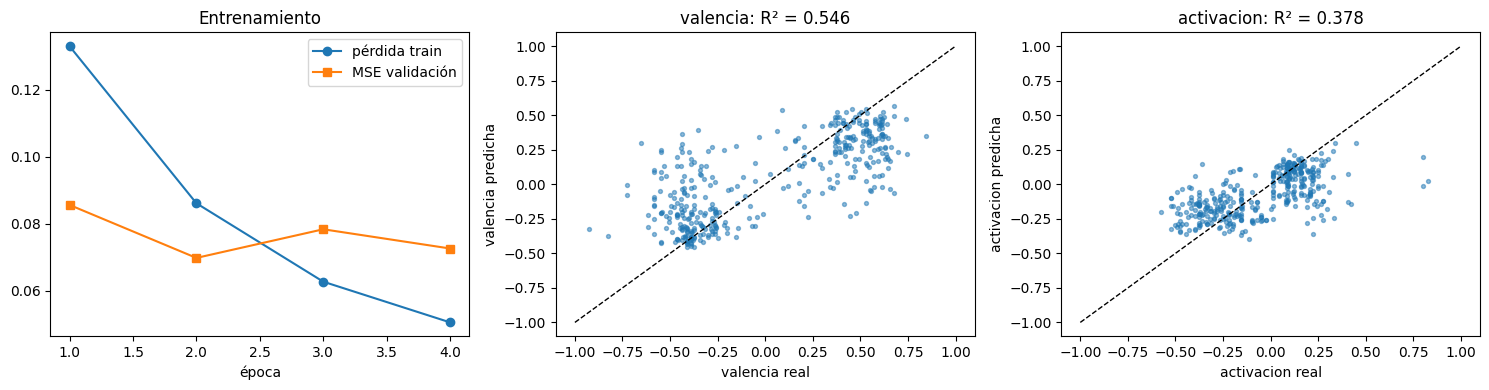

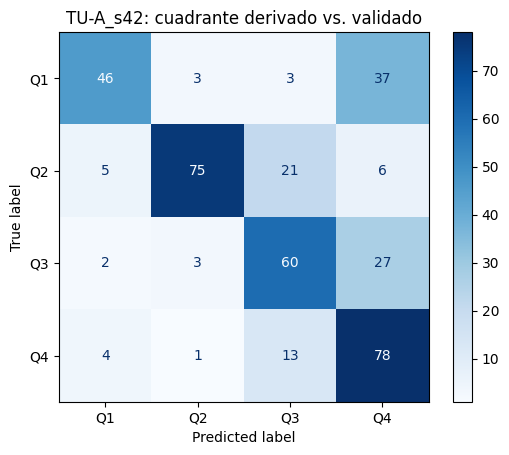

In [6]:
nombre = f'TU-{AGRUPAMIENTOS_A_CORRER[0]}_s{SEMILLAS[0]}{SUFIJO}'
hist = pd.DataFrame(json.load(open(f'{RESULTADOS}/{nombre}/historial.json')))
pred = pd.read_csv(f'{RESULTADOS}/{nombre}/predicciones_test.csv')
r = json.load(open(f'{RESULTADOS}/{nombre}/resultados_test.json'))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(hist.epoca, hist.perdida_reg, 'o-', label='pérdida train')
ax[0].plot(hist.epoca, hist.val_mse_promedio, 's-', label='MSE validación')
ax[0].set_xlabel('época'); ax[0].legend(); ax[0].set_title('Entrenamiento')
for k, d in enumerate(['valencia', 'activacion'], start=1):
    ax[k].scatter(pred[d], pred[d + '_pred'], s=8, alpha=.5)
    ax[k].plot([-1, 1], [-1, 1], 'k--', lw=1)
    ax[k].set_xlabel(f'{d} real'); ax[k].set_ylabel(f'{d} predicha')
    ax[k].set_title(f'{d}: R² = {r["r2_" + d]:.3f}')
plt.tight_layout(); plt.savefig(f'{RESULTADOS}/{nombre}/graficos.png', dpi=150); plt.show()

from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
ConfusionMatrixDisplay(np.array(r['matriz_confusion']), display_labels=CUADRANTES).plot(cmap='Blues')
plt.title(f'{nombre}: cuadrante derivado vs. validado'); plt.show()